# Solutions to notebook 12: Lagrangian mechanics: from energies to a chaotic double pendulum

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/sympy-for-engineers/blob/main/solutions/12_lagrangian_mechanics.ipynb)

Worked solutions to the exercises at the end of [notebook 12](../notebooks/12_lagrangian_mechanics.ipynb).
Try each exercise yourself before reading its solution: the struggle is where the learning happens.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp
from sympy.calculus.euler import euler_equations

sp.init_printing(use_latex="mathjax")
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

t = sp.symbols("t")
m, l, g = sp.symbols("m l g", positive=True)

A note on signs: `euler_equations` returns each equation as
$\dfrac{\partial\mathcal{L}}{\partial q} - \dfrac{d}{dt}\dfrac{\partial\mathcal{L}}{\partial\dot q} = 0$,
which is the equation in the lesson multiplied by $-1$.

## Exercise 1

A bead slides without friction on a parabola $y = a x^2$ under gravity. Derive its equation
of motion with $x$ as the coordinate, and find the frequency of small oscillations.

The recipe of section 12.1: write the position, differentiate for the velocity, form the
energies. The constraint $y = ax^2$ is built into the position, so $x$ is the only coordinate.

In [2]:
a = sp.symbols("a", positive=True)
x = sp.Function("x")(t)

y = a * x**2
T = sp.simplify(m * (x.diff(t) ** 2 + y.diff(t) ** 2) / 2)
V = m * g * y

bead = euler_equations(T - V, x, t)[0]
bead_acceleration = sp.solve(bead, x.diff(t, 2))[0]
bead_acceleration

    ⎛                2    ⎞     
    ⎜      ⎛d       ⎞     ⎟     
2⋅a⋅⎜- 2⋅a⋅⎜──(x(t))⎟  - g⎟⋅x(t)
    ⎝      ⎝dt      ⎠     ⎠     
────────────────────────────────
            2  2                
         4⋅a ⋅x (t) + 1         

In [3]:
# verify against the equation derived by hand: (1 + 4a²x²) x'' + 4a² x x'² + 2 g a x = 0
by_hand = -(4 * a**2 * x * x.diff(t) ** 2 + 2 * g * a * x) / (1 + 4 * a**2 * x**2)
assert sp.simplify(bead_acceleration - by_hand) == 0

For small oscillations, linearize about the rest position $x = 0$, $\dot x = 0$ as in
notebook 9: $\ddot x \approx -\omega^2 x$ with $\omega^2 = -\partial\ddot x/\partial x$.

In [4]:
xs, vs = sp.symbols("x v")
acceleration_xv = bead_acceleration.subs({x.diff(t): vs, x: xs})        # derivative first

omega_squared = -sp.diff(acceleration_xv, xs).subs({xs: 0, vs: 0})
omega_squared

2⋅a⋅g

**Verify.** The parabola has radius of curvature $1/(2a)$ at its lowest point, so near the
bottom the bead moves like a pendulum of length $l = 1/(2a)$, for which $\omega^2 = g/l = 2ga$.
A simulation gives a second check: with $a = 1$ m⁻¹ and a 1 cm amplitude the period must be
$2\pi/\sqrt{2ga} = 1.4185$ s, and the energy per unit mass must stay constant.

In [5]:
assert sp.simplify(omega_squared - 2 * g * a) == 0

numbers = {a: 1.0, g: 9.81}
bead_rhs = sp.lambdify((xs, vs), [vs, acceleration_xv.subs(numbers)], "numpy")
energy_per_mass = sp.simplify((T + V) / m)               # simplify cancels m, which has no number here
bead_energy = sp.lambdify((xs, vs), energy_per_mass.subs({x.diff(t): vs, x: xs}).subs(numbers), "numpy")

def bead_period(amplitude):
    """Period of the bead released from rest at x = amplitude (m), and the largest energy drift."""
    times = np.linspace(0, 10, 20001)
    sol = solve_ivp(lambda _, s: bead_rhs(*s), [0, 10], [amplitude, 0.0], t_eval=times, rtol=1e-10, atol=1e-12)
    position = sol.y[0]
    crossings = times[1:][(position[:-1] < 0) & (position[1:] >= 0)]
    energy = bead_energy(*sol.y)
    return np.diff(crossings).mean(), np.abs(energy - energy[0]).max()

period_theory = 2 * np.pi / np.sqrt(2 * 9.81 * 1.0)
for amplitude in (0.01, 0.5, 1.0):
    period, drift = bead_period(amplitude)
    print(f"amplitude {amplitude:4.2f} m: period {period:.4f} s    energy drift {drift:.1e} J/kg")
    assert drift < 1e-6
print(f"small-oscillation theory:  {period_theory:.4f} s")
assert abs(bead_period(0.01)[0] / period_theory - 1) < 1e-3

amplitude 0.01 m: period 1.4187 s    energy drift 2.4e-12 J/kg
amplitude 0.50 m: period 1.7249 s    energy drift 1.9e-09 J/kg


amplitude 1.00 m: period 2.3797 s    energy drift 1.7e-08 J/kg
small-oscillation theory:  1.4185 s


**Answer.** The equation of motion is

$$\left(1 + 4a^2x^2\right)\ddot x + 4a^2x\,\dot x^2 + 2ga\,x = 0 ,$$

and the mass cancels. For small oscillations $\ddot x = -2ga\,x$, so
$\omega = \sqrt{2ga}$, the frequency of a pendulum whose length is the radius of curvature
$1/(2a)$. With $a = 1$ m⁻¹ the period is 1.42 s. The simulation shows the period growing with
amplitude (1.72 s at 0.5 m and 2.38 s at 1 m): the linear result holds only near the bottom.

## Exercise 2

A pendulum hangs from a cart of mass $M$ that rolls freely on a horizontal track. Derive
both equations of motion and show that the total horizontal momentum is conserved.

The coordinates are the cart position $X$ and the pendulum angle $\theta$ from the vertical.
The bob (mass $m$, rod length $l$) is at $(X + l\sin\theta,\; -l\cos\theta)$.

In [6]:
M = sp.symbols("M", positive=True)
X = sp.Function("X")(t)
theta = sp.Function("theta")(t)

x_bob, y_bob = X + l * sp.sin(theta), -l * sp.cos(theta)
T = sp.simplify(M * X.diff(t) ** 2 / 2 + m * (x_bob.diff(t) ** 2 + y_bob.diff(t) ** 2) / 2)
V = m * g * y_bob
lagrangian = T - V

cart_equation, pendulum_equation = euler_equations(lagrangian, [X, theta], t)
sp.simplify(cart_equation.lhs), sp.simplify(pendulum_equation.lhs)

⎛     2            ⎛                        2                2           2     ↪
⎜    d             ⎜              ⎛d       ⎞                d           d      ↪
⎜- M⋅───(X(t)) - m⋅⎜- l⋅sin(θ(t))⋅⎜──(θ(t))⎟  + l⋅cos(θ(t))⋅───(θ(t)) + ───(X( ↪
⎜      2           ⎜              ⎝dt      ⎠                  2           2    ↪
⎝    dt            ⎝                                        dt          dt     ↪

↪    ⎞       ⎛                 2                     2       ⎞⎞
↪    ⎟       ⎜                d                     d        ⎟⎟
↪ t))⎟, -l⋅m⋅⎜g⋅sin(θ(t)) + l⋅───(θ(t)) + cos(θ(t))⋅───(X(t))⎟⎟
↪    ⎟       ⎜                  2                     2      ⎟⎟
↪    ⎠       ⎝                dt                    dt       ⎠⎠

In [7]:
# verify against the equations derived by hand (Newton's law for the whole system, and the
# pendulum equation with the extra term from the cart's acceleration)
X_dd, theta_dd = X.diff(t, 2), theta.diff(t, 2)
hand_cart = (M + m) * X_dd + m * l * (theta_dd * sp.cos(theta) - theta.diff(t) ** 2 * sp.sin(theta))
hand_pendulum = l * theta_dd + X_dd * sp.cos(theta) + g * sp.sin(theta)
assert sp.simplify(cart_equation.lhs + hand_cart) == 0
assert sp.simplify(pendulum_equation.lhs + m * l * hand_pendulum) == 0

**Momentum.** The momentum that belongs to the coordinate $X$ is
$p = \partial\mathcal{L}/\partial\dot X$. Lagrange's equation for $X$ reads
$\dot p = \partial\mathcal{L}/\partial X$, and $\mathcal{L}$ does not contain $X$ at all.

In [8]:
momentum = sp.diff(lagrangian, X.diff(t))
momentum

               ⎛              d            d       ⎞
             m⋅⎜2⋅l⋅cos(θ(t))⋅──(θ(t)) + 2⋅──(X(t))⎟
  d            ⎝              dt           dt      ⎠
M⋅──(X(t)) + ───────────────────────────────────────
  dt                            2                   

In [9]:
# p is the total horizontal momentum: (mass × horizontal velocity) of the cart plus the bob
assert sp.simplify(momentum - (M * X.diff(t) + m * x_bob.diff(t))) == 0
assert sp.diff(lagrangian, X) == 0

# its time derivative vanishes when the accelerations obey the equations of motion
accelerations = sp.solve([cart_equation, pendulum_equation], [X_dd, theta_dd], dict=True)[0]
assert sp.simplify(momentum.diff(t).subs(accelerations)) == 0

# limiting case: an infinitely heavy cart does not move, leaving the simple pendulum of 12.1
assert sp.limit(accelerations[theta_dd], M, sp.oo) == -g * sp.sin(theta) / l
assert sp.limit(accelerations[X_dd], M, sp.oo) == 0

**Answer.** The equations of motion are

$$(M + m)\,\ddot X + ml\left(\ddot\theta\cos\theta - \dot\theta^2\sin\theta\right) = 0, \qquad
l\,\ddot\theta + \ddot X\cos\theta + g\sin\theta = 0 .$$

The first is the time derivative of
$p = (M + m)\dot X + ml\,\dot\theta\cos\theta$, the total horizontal momentum of cart and
bob, so $p$ is constant. The reason is that $X$ does not appear in the Lagrangian: moving the
whole system along the track changes nothing, and no external horizontal force acts. When
the bob swings one way the cart rolls the other way.

## Exercise 3

Add a spring to the simple pendulum (the rod can stretch, coordinate $r$). Derive the two
equations and simulate the motion for $m = 1$ kg, stiffness $k = 40$ N/m and unstretched
length $l_0 = 1$ m, released from rest at 60° with the spring at its hanging length
$l_0 + mg/k$.

The rod is replaced by a spring of stiffness $k$ and unstretched length $l_0$. The mass is at
$(r\sin\theta,\; -r\cos\theta)$, and the spring adds the potential energy $\tfrac12 k (r - l_0)^2$.

In [10]:
k, l0 = sp.symbols("k l_0", positive=True)
r = sp.Function("r")(t)

x_m, y_m = r * sp.sin(theta), -r * sp.cos(theta)
T = sp.simplify(m * (x_m.diff(t) ** 2 + y_m.diff(t) ** 2) / 2)
V = m * g * y_m + k * (r - l0) ** 2 / 2

radial_equation, angular_equation = euler_equations(T - V, [r, theta], t)
sp.simplify(radial_equation.lhs), sp.simplify(angular_equation.lhs)

⎛                                                 2      2            ⎛        ↪
⎜                                       ⎛d       ⎞      d             ⎜        ↪
⎜g⋅m⋅cos(θ(t)) + k⋅(l₀ - r(t)) + m⋅r(t)⋅⎜──(θ(t))⎟  - m⋅───(r(t)), -m⋅⎜g⋅sin(θ ↪
⎜                                       ⎝dt      ⎠        2           ⎜        ↪
⎝                                                       dt            ⎝        ↪

↪              2                             ⎞     ⎞
↪             d             d        d       ⎟     ⎟
↪ (t)) + r(t)⋅───(θ(t)) + 2⋅──(r(t))⋅──(θ(t))⎟⋅r(t)⎟
↪               2           dt       dt      ⎟     ⎟
↪             dt                             ⎠     ⎠

In [11]:
spring_acc = sp.solve([radial_equation, angular_equation], [r.diff(t, 2), theta.diff(t, 2)], dict=True)[0]
r_dd = sp.simplify(spring_acc[r.diff(t, 2)])
th_dd = sp.simplify(spring_acc[theta.diff(t, 2)])

# verify against the hand-derived equations in polar coordinates
assert sp.simplify(r_dd - (r * theta.diff(t) ** 2 + g * sp.cos(theta) - k * (r - l0) / m)) == 0
assert sp.simplify(th_dd - (-g * sp.sin(theta) - 2 * r.diff(t) * theta.diff(t)) / r) == 0

# verify: hanging at rest, the spring stretches by the weight divided by the stiffness
at_rest = {r.diff(t): 0, theta.diff(t): 0, theta: 0}
assert sp.solve(r_dd.subs(at_rest), r) == [l0 + m * g / k]
r_dd, th_dd

⎛                  ⎛                             2⎞                            ↪
⎜                  ⎜                   ⎛d       ⎞ ⎟   ⎛                d       ↪
⎜k⋅l₀ - k⋅r(t) + m⋅⎜g⋅cos(θ(t)) + r(t)⋅⎜──(θ(t))⎟ ⎟  -⎜g⋅sin(θ(t)) + 2⋅──(r(t) ↪
⎜                  ⎝                   ⎝dt      ⎠ ⎠   ⎝                dt      ↪
⎜──────────────────────────────────────────────────, ───────────────────────── ↪
⎝                        m                                           r(t)      ↪

↪             ⎞
↪   d       ⎞ ⎟
↪ )⋅──(θ(t))⎟ ⎟
↪   dt      ⎠ ⎟
↪ ────────────⎟
↪             ⎠

**Simulation**, following section 12.3. Take $m = 1$ kg, $k = 40$ N/m, $l_0 = 1$ m, so the
spring hangs at rest with length $l_0 + mg/k = 1.245$ m. Release the mass from rest at that
length and $\theta = 60°$.

In [12]:
rs, qs, vr, ws = sp.symbols("r theta v_r omega")
to_symbols = {r.diff(t): vr, theta.diff(t): ws, r: rs, theta: qs}       # derivatives first
spring_values = {m: 1.0, k: 40.0, l0: 1.0, g: 9.81}

spring_rhs = sp.lambdify((rs, qs, vr, ws),
                         [vr, ws, r_dd.subs(to_symbols).subs(spring_values), th_dd.subs(to_symbols).subs(spring_values)],
                         "numpy")
spring_energy = sp.lambdify((rs, qs, vr, ws), (T + V).subs(to_symbols).subs(spring_values), "numpy")

times = np.linspace(0, 15, 3001)
start = [1.0 + 1.0 * 9.81 / 40.0, np.radians(60), 0.0, 0.0]
sol = solve_ivp(lambda _, state: spring_rhs(*state), [0, 15], start, t_eval=times, rtol=1e-10, atol=1e-10)
length, angle = sol.y[0], sol.y[1]

# verify: no friction, so the total energy must stay constant
E = spring_energy(*sol.y)
drift = np.abs(E - E[0]).max()
print(f"initial energy {E[0]:.4f} J     largest drift over 15 s: {drift:.1e} J")
print(f"length between {length.min():.3f} and {length.max():.3f} m     largest angle {np.degrees(np.abs(angle).max()):.1f}°")
assert drift < 1e-6

initial energy -4.9050 J     largest drift over 15 s: 2.1e-08 J
length between 0.866 and 1.709 m     largest angle 60.0°


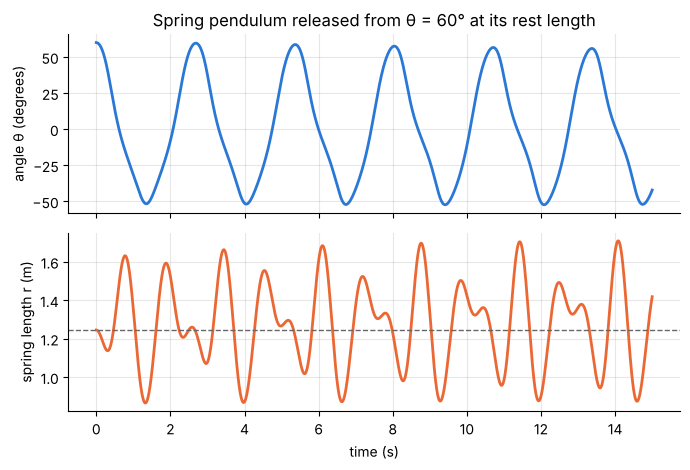

In [13]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(7, 4.8), sharex=True)
top.plot(times, np.degrees(angle))
top.set(ylabel="angle θ (degrees)", title="Spring pendulum released from θ = 60° at its rest length")
bottom.plot(times, length, color="#eb6834")
bottom.axhline(start[0], color="0.4", lw=1, ls="--")
bottom.set(xlabel="time (s)", ylabel="spring length r (m)")
fig.tight_layout()

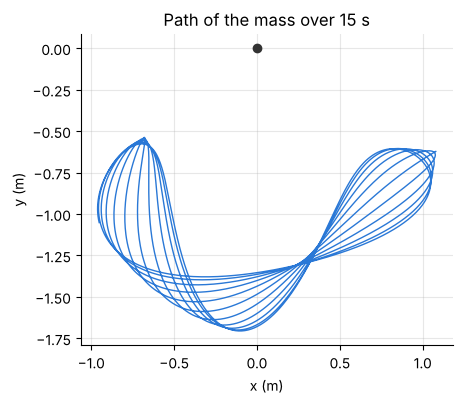

In [14]:
fig, ax = plt.subplots(figsize=(4.8, 4.4))
ax.plot(length * np.sin(angle), -length * np.cos(angle), lw=1)
ax.plot(0, 0, "o", color="0.2", ms=6)
ax.set(xlabel="x (m)", ylabel="y (m)", aspect="equal", title="Path of the mass over 15 s");

**Answer.** The two equations are

$$\ddot r = r\,\dot\theta^2 + g\cos\theta - \frac{k}{m}(r - l_0), \qquad
r\,\ddot\theta + 2\dot r\,\dot\theta + g\sin\theta = 0 .$$

The radial equation contains the centripetal term $r\dot\theta^2$ and the angular equation
the Coriolis term $2\dot r\dot\theta$. These couple the swing to the stretch: although the
spring starts at its rest length, the swing sets it bouncing, and energy passes back and forth
between the two motions. The dashed line is the rest length 1.245 m. The total energy stays
constant to better than $10^{-6}$ J.

## Exercise 4

Start the double pendulum from 10° and 10°. Is the motion still sensitive to the initial
conditions? Repeat 12.5 and compare the growth.

First rebuild the model of sections 12.2 and 12.3.

In [15]:
m1, m2, l1, l2 = sp.symbols("m_1 m_2 l_1 l_2", positive=True)
th1 = sp.Function("theta_1")(t)
th2 = sp.Function("theta_2")(t)

x1, y1 = l1 * sp.sin(th1), -l1 * sp.cos(th1)
x2, y2 = x1 + l2 * sp.sin(th2), y1 - l2 * sp.cos(th2)

T = sp.simplify(m1 * (x1.diff(t) ** 2 + y1.diff(t) ** 2) / 2 + m2 * (x2.diff(t) ** 2 + y2.diff(t) ** 2) / 2)
V = m1 * g * y1 + m2 * g * y2

equations = euler_equations(T - V, [th1, th2], t)
accelerations = sp.solve(equations, [th1.diff(t, 2), th2.diff(t, 2)], dict=True)[0]
alpha1 = sp.simplify(accelerations[th1.diff(t, 2)])
alpha2 = sp.simplify(accelerations[th2.diff(t, 2)])
assert sp.simplify(alpha1.subs(m2, 0) + g * sp.sin(th1) / l1) == 0       # the check of 12.2

In [16]:
q1, q2, w1, w2 = sp.symbols("q_1 q_2 omega_1 omega_2")
to_symbols = {th1.diff(t): w1, th2.diff(t): w2, th1: q1, th2: q2}       # derivatives first
params = {m1: 1.0, m2: 1.0, l1: 1.0, l2: 1.0, g: 9.81}

rhs = sp.lambdify((q1, q2, w1, w2),
                  [w1, w2, alpha1.subs(to_symbols).subs(params), alpha2.subs(to_symbols).subs(params)], "numpy")
energy = sp.lambdify((q1, q2, w1, w2), (T + V).subs(to_symbols).subs(params), "numpy")

def simulate(theta1_deg, theta2_deg, t_end=20.0, points=2001):
    times = np.linspace(0, t_end, points)
    start = [np.radians(theta1_deg), np.radians(theta2_deg), 0.0, 0.0]
    sol = solve_ivp(lambda _, state: rhs(*state), [0, t_end], start, t_eval=times, rtol=1e-10, atol=1e-10)
    return times, sol.y

Now repeat section 12.5 for both starting positions. In each case a twin is released with
$\theta_1$ larger by one millionth of a radian.

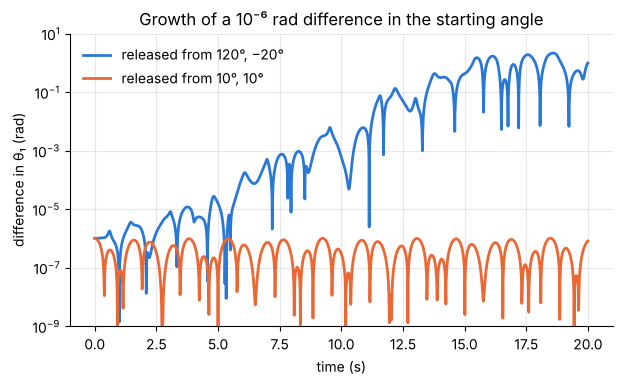

In [17]:
shift = np.degrees(1e-6)
times, large = simulate(120, -20)
_, large_twin = simulate(120 + shift, -20)
_, small = simulate(10, 10)
_, small_twin = simulate(10 + shift, 10)

separation_large = np.abs(large[0] - large_twin[0])
separation_small = np.abs(small[0] - small_twin[0])

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.semilogy(times, separation_large, label="released from 120°, −20°")
ax.semilogy(times, separation_small, label="released from 10°, 10°")
ax.set(xlabel="time (s)", ylabel="difference in θ₁ (rad)", ylim=(1e-9, 10),
       title="Growth of a 10⁻⁶ rad difference in the starting angle")
ax.legend(frameon=False, loc="upper left");

**Verify.** Both runs must conserve energy, otherwise the comparison says nothing. For small
angles there is also a prediction. The linear model of section 12.4 is a sum of the two normal
modes, and the starting difference $(10^{-6}, 0)$ excites both equally, so the difference in
$\theta_1$ should be $10^{-6}\times\tfrac12(\cos\omega_1 t + \cos\omega_2 t)$ with
$\omega^2 = (2 \mp \sqrt2)\,g/l$. It can never exceed $10^{-6}$ rad.

In [18]:
for run in (large, small):
    E = energy(*run)
    assert np.abs(E - E[0]).max() < 1e-5

omega_slow, omega_fast = np.sqrt((2 - np.sqrt(2)) * 9.81), np.sqrt((2 + np.sqrt(2)) * 9.81)
linear_prediction = 1e-6 * (np.cos(omega_slow * times) + np.cos(omega_fast * times)) / 2
signed_small = small_twin[0] - small[0]

growth_large = separation_large.max() / 1e-6
growth_small = separation_small.max() / 1e-6
print(f"120°, −20°: the difference grows by a factor of about {growth_large:,.0f}")
print(f"10°, 10°:   the difference grows by a factor of {growth_small:.2f}")
print(f"largest deviation from the linear prediction: {np.abs(signed_small - linear_prediction).max():.1e} rad")

assert growth_large > 1e4
assert growth_small < 2
assert np.abs(signed_small - linear_prediction).max() < 3e-7

120°, −20°: the difference grows by a factor of about 2,140,612
10°, 10°:   the difference grows by a factor of 1.01
largest deviation from the linear prediction: 1.9e-07 rad


**Answer.** No. From 10° and 10° the two pendulums stay together: the difference in
$\theta_1$ oscillates and stays of the order of the initial $10^{-6}$ rad for the whole 20 s,
as the linear model predicts. From 120° and −20° the same difference grows roughly
exponentially, by a factor of more than a million. At small amplitude the equations are nearly
linear, the motion is a sum of two normal modes, and a linear system cannot amplify a
disturbance without limit. Chaos needs the nonlinear terms, which only matter at large angles.

## Exercise 5

With equal lengths, make the lower mass ten times heavier. How do the two normal-mode
frequencies change?

Repeat section 12.4 with equal lengths but a general mass ratio $\mu = m_2/m_1$, then set
$\mu = 10$.

In [19]:
mass_ratio = sp.symbols("mu", positive=True)

acc = sp.Matrix([alpha1, alpha2]).subs(to_symbols)
at_rest = {q1: 0, q2: 0, w1: 0, w2: 0}
stiffness = -acc.jacobian([q1, q2]).subs(at_rest).subs({m2: mass_ratio * m1, l2: l1})    # θ'' = -K θ
stiffness = sp.simplify(stiffness)

heavy = sorted((sp.radsimp(sp.simplify(val)) for val in stiffness.subs(mass_ratio, 10).eigenvals()),
               key=lambda val: float(val.subs({g: 1, l1: 1})))
heavy

⎡g⋅(11 - √110)  g⋅(√110 + 11)⎤
⎢─────────────, ─────────────⎥
⎣     l₁             l₁      ⎦

**Verify by hand.** The linearized equations for equal lengths are
$(1+\mu)\,l\ddot\theta_1 + \mu\,l\ddot\theta_2 + (1+\mu)\,g\theta_1 = 0$ and
$l\ddot\theta_1 + l\ddot\theta_2 + g\theta_2 = 0$. Looking for solutions that vary as
$\cos\omega t$ gives $(1+\mu)(1-\lambda)^2 = \mu\lambda^2$ with $\lambda = \omega^2 l/g$, so

$$\omega^2 = \frac{g}{l}\,\frac{1}{1 \pm \sqrt{\mu/(1+\mu)}} .$$

In [20]:
by_hand = [g / l1 / (1 + sign * sp.sqrt(mass_ratio / (1 + mass_ratio))) for sign in (1, -1)]    # slow, fast

# the hand formula satisfies the characteristic equation of the stiffness matrix for any mass ratio
for value in by_hand:
    assert sp.simplify((stiffness - value * sp.eye(2)).det()) == 0
# it gives the computed values at mu = 10, and the lesson's (2 ∓ √2) g/l at mu = 1
assert all(sp.simplify(hand.subs(mass_ratio, 10) - value) == 0 for hand, value in zip(by_hand, heavy))
assert sp.simplify(by_hand[0].subs(mass_ratio, 1) - (2 - sp.sqrt(2)) * g / l1) == 0
assert sp.simplify(by_hand[1].subs(mass_ratio, 1) - (2 + sp.sqrt(2)) * g / l1) == 0
# a very heavy lower mass: the slow mode becomes a simple pendulum of length 2l
assert sp.limit(by_hand[0], mass_ratio, sp.oo) == g / (2 * l1)

In [21]:
numbers = {g: 9.81, l1: 1.0}
print("m2/m1    slow mode: ω (rad/s), period (s)    fast mode: ω (rad/s), period (s)")
for ratio in (1, 10):
    slow, fast = (float(sp.sqrt(value.subs(mass_ratio, ratio).subs(numbers))) for value in by_hand)
    print(f"{ratio:5d}    {slow:14.3f} {2 * np.pi / slow:11.3f}    {fast:19.3f} {2 * np.pi / fast:11.3f}")

m2/m1    slow mode: ω (rad/s), period (s)    fast mode: ω (rad/s), period (s)
    1             2.397       2.621                  5.787       1.086
   10             2.241       2.804                 14.519       0.433


A simulation gives one more check, as in section 12.4: a small swing started in the slow mode
shape of the heavy system must keep the predicted period.

In [22]:
heavy_params = {m1: 1.0, m2: 10.0, l1: 1.0, l2: 1.0, g: 9.81}
heavy_rhs = sp.lambdify((q1, q2, w1, w2),
                        [w1, w2, alpha1.subs(to_symbols).subs(heavy_params), alpha2.subs(to_symbols).subs(heavy_params)],
                        "numpy")

slow_value, _, slow_vectors = min(stiffness.subs(mass_ratio, 10).subs(numbers).eigenvects(), key=lambda item: item[0])
ratio = float(slow_vectors[0][1] / slow_vectors[0][0])                 # θ₂/θ₁ in the slow mode
ts = np.linspace(0, 30, 6001)
swing = solve_ivp(lambda _, state: heavy_rhs(*state), [0, 30], [np.radians(1.0), np.radians(ratio), 0.0, 0.0],
                  t_eval=ts, rtol=1e-10, atol=1e-10).y
crossings = ts[1:][(swing[0][:-1] < 0) & (swing[0][1:] >= 0)]
period_sim = np.diff(crossings).mean()
period_theory = 2 * np.pi / np.sqrt(float(slow_value))
print(f"slow mode: θ₂/θ₁ = {ratio:.3f}    period from simulation {period_sim:.4f} s    theory {period_theory:.4f} s")
assert abs(period_sim / period_theory - 1) < 1e-3

slow mode: θ₂/θ₁ = 1.049    period from simulation 2.8039 s    theory 2.8038 s


**Answer.** For $m_2 = 10\,m_1$ and equal lengths,

$$\omega^2 = \left(11 \mp \sqrt{110}\right)\frac{g}{l} \approx 0.512\,\frac{g}{l}
\quad\text{and}\quad 21.5\,\frac{g}{l},$$

compared with $(2 \mp \sqrt2)\,g/l \approx 0.586\,g/l$ and $3.41\,g/l$ for equal masses. With
$l = 1$ m the slow mode goes from 2.40 to 2.24 rad/s (period 2.62 to 2.80 s) and the fast mode
from 5.79 to 14.5 rad/s (period 1.09 to 0.43 s). The two frequencies move apart. In the slow
mode the heavy lower mass dominates and the system approaches a single pendulum of length
$2l$, for which $\omega^2 = g/(2l)$. In the fast mode the heavy mass barely moves and the light
upper mass vibrates quickly between the pivot and the taut lower rod.